In [1]:
import numpy as np
import pandas as pd

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RANSACRegressor, TheilSenRegressor
import warnings
warnings.filterwarnings("ignore")

In [2]:
# ! unzip phones.zip

Ранее мы посмотрели простой вариант анализа данных, где почти все столбцы имеют численные значения, количество категорий не велико и нет пропусков. Но часто приходится работать с "сырыми" данными, где могут присутствовать текстовые признаки, из которых необходимо извлечь что-то полезное.

Сейчас мы поупражняемся в **Feature Engineering**.

Набор данных содержит информацию о мобильных телефонах. Набор данных взят с сайта [kaggle](https://www.kaggle.com/datasets/demonllord/indian-smartphones-under-20000specs-prices/data).

In [3]:
df = pd.read_csv("task/indian_smartphones_under_20000_raw.csv", index_col=0)
print("Количество строк: ", len(df))
df.head()

Количество строк:  11976


,Model Name,Price,Percentage Discount,Ratings,Reviews,RAM & ROM,Display Size,Camera,Battery Capacity,Processor,Warranty
0,"vivo T4x 5G (Pronto Purple, 256 GB)",18499.0,11% off,151361.0,7146.0,8 GB RAM | 256 GB ROM,17.07 cm (6.72 inch) Display,50MP + 2MP | 8MP Front Camera,6500 mAh Battery,Dimensity 7300 5G Processor,1 Year Warranty for Device and 6 Months Warran...
1,"MOTOROLA G96 5G (Pantone Ashleigh Blue, 256 GB)",18999.0,17% off,81989.0,4125.0,8 GB RAM | 256 GB ROM,16.94 cm (6.67 inch) Full HD+ Display,50MP + 8MP | 32MP Front Camera,5500 mAh Battery,7s Gen 2 Processor,1 Year Warranty on Handset and 6 Months Warran...
2,"vivo T4x 5G (Pronto Purple, 128 GB)",16499.0,15% off,151361.0,7146.0,8 GB RAM | 128 GB ROM,17.07 cm (6.72 inch) Display,50MP + 2MP | 8MP Front Camera,6500 mAh Battery,Dimensity 7300 5G Processor,1 Year Warranty for Device and 6 Months Warran...
3,"MOTOROLA G96 5G (Pantone Greener Pastures, 256...",18999.0,17% off,81989.0,4125.0,8 GB RAM | 256 GB ROM,16.94 cm (6.67 inch) Full HD+ Display,50MP + 8MP | 32MP Front Camera,5500 mAh Battery,7s Gen 2 Processor,1 Year Warranty on Handset and 6 Months Warran...
4,"realme P4x 5G (Lake Green, 256 GB)",17499.0,16% off,1211.0,125.0,8 GB RAM | 256 GB ROM,17.07 cm (6.72 inch) Full HD+ Display,50MP + 2MP | 8MP Front Camera,7000 mAh Battery,Dimensity 7400 Ultra Processor,1 Year Manufacturer Warranty for Phone and 6 M...


In [4]:
df.drop_duplicates(inplace=True)
print("Количество уникальных строк: ", len(df))

Количество уникальных строк:  823


Во первых, в наборе данных много пустых значений:

In [5]:
df.isna().sum()

Model Name               0
Price                    8
Percentage Discount    100
Ratings                 19
Reviews                 19
RAM & ROM                0
Display Size             0
Camera                   0
Battery Capacity         1
Processor                9
Warranty               218
dtype: int64

Сразу откинем те строки, где нет ценников:

In [6]:
df[df["Price"].isna()]
df = df[df["Price"].notna()]

In [7]:
df.isna().sum()

Model Name               0
Price                    0
Percentage Discount     92
Ratings                 19
Reviews                 19
RAM & ROM                0
Display Size             0
Camera                   0
Battery Capacity         0
Processor                7
Warranty               212
dtype: int64

С другими пропусками мы разберёмся позже.

## Извлечение признаков

Давайте начнём преобразовывать текстовые признаки в числа, которые можно обрабатывать.

Начнём с памяти на устройствах.

In [8]:
df["RAM & ROM"].str.split("|").apply(len).value_counts()

RAM & ROM
3    429
2    386
Name: count, dtype: int64

Есть строчки, делящиеся символом | на 2 и 3 части.

Посмотрим на строчки, где три компоненты, конкретно посмотрим на третью часть:

In [9]:
mask = df["RAM & ROM"].str.split("|").apply(len) == 3
data = df["RAM & ROM"].str.split("|")[mask]

# data
data = data.apply(lambda x: x[2].strip().split(" "))
print("Везде 4 слова:\n\n", data.apply(lambda x: len(x)).value_counts())

words = data.apply(pd.Series)
print(words[0].value_counts())
print(words[1].value_counts())
print(words[2].value_counts())
print(words[3].value_counts())

Везде 4 слова:

 RAM & ROM
4    429
Name: count, dtype: int64
0
Expandable    429
Name: count, dtype: int64
1
Upto    429
Name: count, dtype: int64
2
1       185
2       114
32       44
512      25
256      22
8        16
16       11
128       9
1500      2
64        1
Name: count, dtype: int64
3
TB    299
GB    120
MB     10
Name: count, dtype: int64


Мы узнали, что речь идёт про возможность установки дополнительной памяти. Предпоследнее слово $-$ величина, Последнее слово $-$ единицы измерения.

Теперь разберёмся с первыми двумя компонентами. Проверим, что везде формат `X GB RAM` и `X GB ROM`. Начнём с оперативной памяти:

In [10]:
data = df["RAM & ROM"].str.split("|")


data1 = data.apply(lambda x: x[0].strip().split(" "))
print("Везде 3 слова, но есть и где 4:\n\n", data1.apply(lambda x: len(x)).value_counts())

mask = data1.apply(lambda x: len(x)) == 4
print("Тут снова что-то не так с целыми строчками:")
df[mask]


Везде 3 слова, но есть и где 4:

 RAM & ROM
3    814
4      1
Name: count, dtype: int64
Тут снова что-то не так с целыми строчками:


,Model Name,Price,Percentage Discount,Ratings,Reviews,RAM & ROM,Display Size,Camera,Battery Capacity,Processor,Warranty
324,IAIR Basic Feature Dual Sim Mobile Phone with ...,801.0,52% off,21.0,4.0,0 MB MB ROM | Expandable Upto 32 MB,6.1 cm (2.4 inch) Full HD Display,0.8MP Rear Camera,2800 mAh Battery,1 Years Manufacturer Warranty,NaN


Откинем эту строчку:

In [11]:
data1 = data.apply(lambda x: x[0].strip().split(" "))
mask = data1.apply(lambda x: len(x)) != 4

df = df[mask]

Проверим составляющие:

In [12]:
words = data1.apply(pd.Series)
print(words[1].value_counts())
print("\nГде-то речь не про оперативную память:\n")
print(words[2].value_counts())

1
GB    699
MB    116
Name: count, dtype: int64

Где-то речь не про оперативную память:

2
RAM    809
ROM      5
MB       1
Name: count, dtype: int64


И снова что-то не так с целыми строчками:

In [13]:
mask = words[2] == "ROM"
df[mask]

,Model Name,Price,Percentage Discount,Ratings,Reviews,RAM & ROM,Display Size,Camera,Battery Capacity,Processor,Warranty
328,LAVA A1 Josh,894.0,28% off,9876.0,734.0,0 MB ROM | Expandable Upto 32 GB,4.5 cm (1.77 inch) Quarter QVGA Display,1000 mAh Li-ion Battery,No Warranty,NaN,NaN
376,LAVA A7 Star,1499.0,9% off,21712.0,2241.0,0 GB ROM | Expandable Upto 32 GB,4.5 cm (1.77 inch) Display,0.3MP Rear Camera | 0.3MP Front Camera,1750 mAh Battery,1 year manufacturer Replacement for device and...,NaN
487,IAIR Basic Feature Dual Sim Mobile Phone with ...,799.0,55% off,68.0,16.0,0 MB ROM | Expandable Upto 8 GB,6.1 cm (2.4 inch) Display,0.8MP Rear Camera,2800 mAh Battery,2 Years Manufacturer Warranty,NaN
566,IAIR Basic Feature Dual Sim Mobile Phone with ...,845.0,47% off,41.0,13.0,0 MB ROM | Expandable Upto 32 GB,6.1 cm (2.4 inch) Display,0.8MP Rear Camera,2800 mAh Battery,2 Years Manufacturer Warranty,NaN
573,IAIR Basic Feature Dual Sim Mobile Phone with ...,610.0,59% off,NaN,NaN,0 MB ROM | Expandable Upto 32 GB,4.5 cm (1.77 inch) Display,0.8MP Rear Camera,1000 mAh Battery,2 Years Manufacturer Warranty,NaN


Откинем эти строчки:

In [14]:
mask = words[2] == "RAM"
df = df[mask]


С RAM разобрались, посмотрим на ROM:

In [15]:
data = df["RAM & ROM"].str.split("|")


data1 = data.apply(lambda x: x[1].strip().split(" "))
print("Везде 3 слова, но есть и где 4:\n\n", data1.apply(lambda x: len(x)).value_counts())

mask = data1.apply(lambda x: len(x)) == 4
print("Эта строчка:")
df[mask]


Везде 3 слова, но есть и где 4:

 RAM & ROM
3    808
4      1
Name: count, dtype: int64
Эта строчка:


,Model Name,Price,Percentage Discount,Ratings,Reviews,RAM & ROM,Display Size,Camera,Battery Capacity,Processor,Warranty
449,I Kall K 19 CAr,1305.0,34% off,1771.0,94.0,32 MB RAM | 32 MB/64 MB ROM,4.5 cm (1.77 inch) Display,0.3MP Rear Camera,800 mAh Battery,1 Year warranty for mobile and 6 Months for bo...,NaN


In [16]:
words = data1.apply(pd.Series)
print(words[1].value_counts())
print("\nГде-то речь не про оперативную память:\n")
print(words[2].value_counts())

1
GB       702
MB       105
KB         1
MB/64      1
Name: count, dtype: int64

Где-то речь не про оперативную память:

2
ROM    808
MB       1
Name: count, dtype: int64


Тут аномальная строчка всего одна, её тоже откинем:

In [17]:
mask = data1.apply(lambda x: len(x)) != 4
df = df[mask]

Выделим четыре столбца: размер RAM, ROM, возможность установки дополнительной памяти и её объём. Объём будем измерять в ГБ.

Если дополнительную память установить нельзя введём значение 0. В данном случае корректно обработать данные нам поможет индикаторная переменная, которую мы добавляем. Без такой индикаторной переменной обучаемый вес для размера расширяемой памяти будет искажаться.

In [18]:
def extract_RAM_ROM(x):
    parts = x.split("|")
    result = []
    scale_dict = {"TB":1024, "GB":1, "MB":1/1024, "KB": 1/1024/1024}
    # Извлекаем информацию про RAM
    ram = parts[0].strip().split(" ")
    scale = scale_dict[ram[1]]
    result.append(float(ram[0]) * scale)
    # Извлекаем информацию про ROM
    rom = parts[1].strip().split(" ")
    scale = scale_dict[rom[1]]
    result.append(float(rom[0]) * scale)
    
    if len(parts) == 3:
        external = parts[2].strip().split(" ")
        result.append(True)
        scale = scale_dict[external[-1]]
        result.append(float(external[-2]) * scale)
    else:
        result.append(False)
        result.append(0)
    return result
        
data = df["RAM & ROM"].apply(extract_RAM_ROM)
data

0          [8.0, 256.0, False, 0]
1          [8.0, 256.0, False, 0]
2          [8.0, 128.0, False, 0]
3          [8.0, 256.0, False, 0]
4          [8.0, 256.0, False, 0]
                  ...            
956    [4.0, 128.0, True, 2048.0]
957        [6.0, 128.0, False, 0]
958         [4.0, 64.0, False, 0]
959        [4.0, 128.0, False, 0]
960        [4.0, 128.0, False, 0]
Name: RAM & ROM, Length: 808, dtype: object

In [19]:
data = data.apply(pd.Series)
df["ram"] = data[0]
df["rom"] = data[1]
df["is_extendable"] = data[2]
df["extension_size"] = data[3]
df.head()

,Model Name,Price,Percentage Discount,Ratings,Reviews,RAM & ROM,Display Size,Camera,Battery Capacity,Processor,Warranty,ram,rom,is_extendable,extension_size
0,"vivo T4x 5G (Pronto Purple, 256 GB)",18499.0,11% off,151361.0,7146.0,8 GB RAM | 256 GB ROM,17.07 cm (6.72 inch) Display,50MP + 2MP | 8MP Front Camera,6500 mAh Battery,Dimensity 7300 5G Processor,1 Year Warranty for Device and 6 Months Warran...,8.0,256.0,False,0.0
1,"MOTOROLA G96 5G (Pantone Ashleigh Blue, 256 GB)",18999.0,17% off,81989.0,4125.0,8 GB RAM | 256 GB ROM,16.94 cm (6.67 inch) Full HD+ Display,50MP + 8MP | 32MP Front Camera,5500 mAh Battery,7s Gen 2 Processor,1 Year Warranty on Handset and 6 Months Warran...,8.0,256.0,False,0.0
2,"vivo T4x 5G (Pronto Purple, 128 GB)",16499.0,15% off,151361.0,7146.0,8 GB RAM | 128 GB ROM,17.07 cm (6.72 inch) Display,50MP + 2MP | 8MP Front Camera,6500 mAh Battery,Dimensity 7300 5G Processor,1 Year Warranty for Device and 6 Months Warran...,8.0,128.0,False,0.0
3,"MOTOROLA G96 5G (Pantone Greener Pastures, 256...",18999.0,17% off,81989.0,4125.0,8 GB RAM | 256 GB ROM,16.94 cm (6.67 inch) Full HD+ Display,50MP + 8MP | 32MP Front Camera,5500 mAh Battery,7s Gen 2 Processor,1 Year Warranty on Handset and 6 Months Warran...,8.0,256.0,False,0.0
4,"realme P4x 5G (Lake Green, 256 GB)",17499.0,16% off,1211.0,125.0,8 GB RAM | 256 GB ROM,17.07 cm (6.72 inch) Full HD+ Display,50MP + 2MP | 8MP Front Camera,7000 mAh Battery,Dimensity 7400 Ultra Processor,1 Year Manufacturer Warranty for Phone and 6 M...,8.0,256.0,False,0.0


Далее давайте посмотрим на `Battery Capacity`:

In [20]:
data = df["Battery Capacity"].str.split(" ")
lengths = data.apply(len)
print("Снова разные длины текстов:")

print(lengths.value_counts())

words = data.apply(pd.Series)
# print(words[1].value_counts())
# print("\nГде-то речь не про оперативную память:\n")
print(words[1].value_counts())
mask = words[1] != "mAh"
df[mask]

Снова разные длины текстов:
Battery Capacity
3    672
5     81
4     48
6      4
2      3
Name: count, dtype: int64
1
mAh          802
Months         2
Processor      2
Days           1
Year           1
Name: count, dtype: int64


,Model Name,Price,Percentage Discount,Ratings,Reviews,RAM & ROM,Display Size,Camera,Battery Capacity,Processor,Warranty,ram,rom,is_extendable,extension_size
400,Snexian BOLD 20K PRO,1199.0,40% off,NaN,NaN,32 MB RAM | 32 MB ROM,7.11 cm (2.8 inch) VGA Display,2500 mAh Battery,3 Months Domestic Warranty,NaN,NaN,0.031250,0.031250,False,0.0
436,hmd 105 Dual Sim Keypad Phone with Built-in UP...,950.0,36% off,4322.0,314.0,4 MB RAM | 4 MB ROM | Expandable Upto 32 GB,5.08 cm (2 inch) Display,1000 mAh Battery,SC6531E Processor,1 Year Replacement.,NaN,0.003906,0.003906,True,32.0
474,Nokia 106 Single Sim Keypad Phone with Built-i...,1271.0,25% off,7572.0,406.0,32 MB RAM | 32 MB ROM,17.02 cm (6.7 inch) Display,1000 mAh Battery,SC6531E Processor,1YR BRAND WARRANTY ON HANDSET & 6 MONTHS WARRA...,NaN,0.031250,0.031250,False,0.0
518,Snexian BOLD 777,779.0,48% off,188.0,11.0,32 MB RAM | 32 MB ROM,1.68 cm (0.66 inch) Display,850 mAh Battery,7 Days Warranty,NaN,NaN,0.031250,0.031250,False,0.0
538,I Kall K100,680.0,31% off,10369.0,838.0,32 MB RAM | 32 MB ROM | Expandable Upto 8 GB,4.57 cm (1.8 inch) Display,1000 mAh Battery,12 Months,NaN,NaN,0.031250,0.031250,True,8.0
576,PHILIPS All New E2103 Sleek & Stylish Keypad M...,1139.0,18% off,7.0,1.0,32 MB RAM | 32 MB ROM,4.5 cm (1.77 inch) Display,1000 mAh Battery,One Year manufacturer Warranty,NaN,NaN,0.031250,0.031250,False,0.0


In [21]:
mask = words[1] == "mAh"
df = df[mask]

Давайте проверим каких типов бывают батареи:

In [22]:
data = df["Battery Capacity"].str.split(" ", n=2)
words = data.apply(pd.Series)
words[2].value_counts()

2
Battery                        671
Lithium-ion Polymer Battery     21
Lithium Polymer Battery         17
Lithium Ion Battery             16
Lithium Battery                 14
Li-ion Polymer Battery          12
Lithium-ion Battery              9
Li-ion Battery                   8
Lithium-Ion Polymer Battery      6
Li-polymer Battery               6
Li Polymer Battery               4
Lithium Ion Polymer Battery      4
Li-Polymer Battery               4
Lithium ion Battery              3
Li-Ion Battery                   3
Li-Polymer Battery Battery       1
Lithium polymer Battery          1
Lithium-Ploymer Battery          1
Lithium-polymer Battery          1
Name: count, dtype: int64

In [23]:
df["battery_capacity"] = df["Battery Capacity"].str.split(" ").apply(lambda x: float(x[0]))
df.head()

,Model Name,Price,Percentage Discount,Ratings,Reviews,RAM & ROM,Display Size,Camera,Battery Capacity,Processor,Warranty,ram,rom,is_extendable,extension_size,battery_capacity
0,"vivo T4x 5G (Pronto Purple, 256 GB)",18499.0,11% off,151361.0,7146.0,8 GB RAM | 256 GB ROM,17.07 cm (6.72 inch) Display,50MP + 2MP | 8MP Front Camera,6500 mAh Battery,Dimensity 7300 5G Processor,1 Year Warranty for Device and 6 Months Warran...,8.0,256.0,False,0.0,6500.0
1,"MOTOROLA G96 5G (Pantone Ashleigh Blue, 256 GB)",18999.0,17% off,81989.0,4125.0,8 GB RAM | 256 GB ROM,16.94 cm (6.67 inch) Full HD+ Display,50MP + 8MP | 32MP Front Camera,5500 mAh Battery,7s Gen 2 Processor,1 Year Warranty on Handset and 6 Months Warran...,8.0,256.0,False,0.0,5500.0
2,"vivo T4x 5G (Pronto Purple, 128 GB)",16499.0,15% off,151361.0,7146.0,8 GB RAM | 128 GB ROM,17.07 cm (6.72 inch) Display,50MP + 2MP | 8MP Front Camera,6500 mAh Battery,Dimensity 7300 5G Processor,1 Year Warranty for Device and 6 Months Warran...,8.0,128.0,False,0.0,6500.0
3,"MOTOROLA G96 5G (Pantone Greener Pastures, 256...",18999.0,17% off,81989.0,4125.0,8 GB RAM | 256 GB ROM,16.94 cm (6.67 inch) Full HD+ Display,50MP + 8MP | 32MP Front Camera,5500 mAh Battery,7s Gen 2 Processor,1 Year Warranty on Handset and 6 Months Warran...,8.0,256.0,False,0.0,5500.0
4,"realme P4x 5G (Lake Green, 256 GB)",17499.0,16% off,1211.0,125.0,8 GB RAM | 256 GB ROM,17.07 cm (6.72 inch) Full HD+ Display,50MP + 2MP | 8MP Front Camera,7000 mAh Battery,Dimensity 7400 Ultra Processor,1 Year Manufacturer Warranty for Phone and 6 M...,8.0,256.0,False,0.0,7000.0


<h2>Домашнее задание</h2>

- Обработайте оставшиеся признаки: 
    - `Display Size`
    -  Обратите внимание, что столбец `Warranty` текстовый и имеет сложный формат, необходимо извлечь продолжительность гарантии и обработать пропуски
    - `Processor` Обратите внимание, что столбец  на самом деле видов мобильных процессоров не так много, но их названия написаны по-разному.
    - Из `Model Name` можно попробовать извлечь производителя телефона 
- Попробуйте "отменить" скидку на телефоны


---
# Решение домашнего задания

Ориентир из примера на занятии: $R^2$ на тесте ≈ 0.696, с «отменой» скидки ≈ 0.701.

## 1. Display Size

Строки имеют вид `16.94 cm (6.67 inch) Full HD+ AMOLED Display`. Извлекаю диагональ в дюймах и флаги: Full HD (включая FHD/QHD/Retina), просто HD, AMOLED/OLED.

При проверке распределения нашлась ошибка в данных: у одного телефона (Samsung A16) диагональ 16.91 дюйма. Сначала я её не заметил, и модели с логарифмом цены на одном из фолдов кросс-валидации выдавали для этого телефона цену в 165 тысяч (экспонента от большого линейного предсказания), $R^2$ уходил в минус. Заменяю это значение пропуском.

In [24]:
import re, json
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.metrics import mean_absolute_percentage_error
RESULTS = {}

disp = df["Display Size"].str.lower()
df["display_inch"] = disp.str.extract(r"\(([\d.]+)\s*inch")[0].astype(float)
df["display_fullhd"] = disp.str.contains(r"full hd|fhd|qhd|2k|retina").astype(int)
df["display_hd"] = (disp.str.contains("hd") & ~disp.str.contains(r"full hd|fhd|qhd")).astype(int)
df["display_amoled"] = disp.str.contains("amoled|oled").astype(int)
print("Не удалось извлечь диагональ:", df["display_inch"].isna().sum())
# ошибка в данных: у Samsung A16 указано 42.95 cm (16.91 inch) — планшетов в наборе нет, это опечатка.
# Крошечные диагонали (0.66–1.5 дюйма) — реальные мини-телефоны Kechaoda, их не трогаю.
print(df.loc[df["display_inch"] > 8, ["Model Name", "Display Size"]])
df.loc[df["display_inch"] > 8, "display_inch"] = np.nan   # потом заполню медианой
df[["Display Size", "display_inch", "display_fullhd", "display_hd", "display_amoled"]].sample(6, random_state=0)

Не удалось извлечь диагональ: 0
                            Model Name  \
497  Samsung A16 (Light Green, 128 GB)   

                                          Display Size  
497  42.95 cm (16.91 inch) Full HD+ E3 Super AMOLED...  


,Display Size,display_inch,display_fullhd,display_hd,display_amoled
8,17.02 cm (6.7 inch) Super HD Display,6.70,0,1,0
300,16.94 cm (6.67 inch) Full HD+ Display,6.67,1,0,0
89,16.94 cm (6.67 inch) Full HD+ Display,6.67,1,0,0
515,17.02 cm (6.7 inch) HD+ Display,6.70,0,1,0
14,17.02 cm (6.7 inch) Super HD Display,6.70,0,1,0
537,4.5 cm (1.77 inch) NA Display,1.77,0,0,0


## 2. Warranty

Во-первых, в части строк столбцы «съехали»: в `Processor` записан текст гарантии (например, `1 Year Manufacturer Warranty for Phone...`), а `Warranty` пустой. Такие строки нахожу по отсутствию слова «processor» и наличию слов про год/месяц/гарантию — переношу текст в гарантию, а процессор считаю неизвестным.

Во-вторых, формат текста гарантии очень разный: `1 Year ...`, `12 Months Brand warranty`, `One Year for Handset...`, `1YR BRAND WARRANTY`, `NO WARRANTY`, просто `1`. Извлекаю **первую** упомянутую длительность (это гарантия на сам телефон, дальше обычно идёт гарантия на аксессуары) и перевожу в месяцы. Иногда в `Warranty` вообще лежит описание характеристик (`120Hz Refresh Rate`) — такие значения считаю пропусками.

Пропуски заполняю медианой (12 месяцев — у подавляющего большинства телефонов гарантия 1 год) и добавляю индикатор пропуска, чтобы модель могла отдельно учесть «гарантия не указана».

In [25]:
proc_raw = df["Processor"].fillna("")
looks_like_warranty = (~proc_raw.str.contains("processor", case=False)
                       & proc_raw.str.contains(r"warrant|year|month|^\s*\d+\s*$", case=False))
warranty_text = df["Warranty"].copy()
moved = looks_like_warranty & warranty_text.isna()
warranty_text[moved] = proc_raw[moved]
proc_text = proc_raw.where(~looks_like_warranty, "")
print(f"Строк, где гарантия записана в столбец Processor: {looks_like_warranty.sum()}")

NUM_WORDS = {"one": 1, "two": 2, "three": 3}
def warranty_months(s):
    if not isinstance(s, str):
        return np.nan
    s = s.lower()
    if "no warranty" in s:
        return 0.0
    m = re.search(r"(\d+|one|two|three)\s*-?\s*(years?|yrs?|months?|days?)", s)
    if m:
        value = NUM_WORDS.get(m.group(1))
        value = float(m.group(1)) if value is None else value
        unit = m.group(2)
        return value * 12 if unit.startswith("y") else value / 30 if unit.startswith("d") else value
    if re.fullmatch(r"\s*\d+\s*", s):     # просто число — это годы
        return float(s) * 12
    return np.nan

df["warranty_months"] = warranty_text.apply(warranty_months)
print("Не распознано (будет пропуском):")
print(warranty_text[df["warranty_months"].isna() & warranty_text.notna()].str[:60].value_counts().head(8))
df["warranty_missing"] = df["warranty_months"].isna().astype(int)
df["warranty_months"] = df["warranty_months"].clip(0, 24).fillna(df["warranty_months"].median())
print("\nРаспределение после обработки:")
print(df["warranty_months"].round(1).value_counts())

Строк, где гарантия записана в столбец Processor: 196
Не распознано (будет пропуском):
Warranty
Splash Proof - Protected by P2i                                 4
Max GPU Frequency: 950 MHz, Supports GAME Turbo 3.0, UFS2.2     4
120Hz Refresh Rate                                              3
Multiple Hands-free Voice Assistants                            3
65W Super Dart Charger                                          3
80W SUPERVOOC Charger                                           2
Brand Warranty                                                  2
90Hz Refresh Rate AMOLED Display                                2
Name: count, dtype: int64

Распределение после обработки:
warranty_months
12.0    778
24.0      8
0.0       5
1.0       5
6.0       3
3.3       1
3.0       1
0.2       1
Name: count, dtype: int64


## 3. Processor

Разных строк больше двухсот, но семейств процессоров немного: MediaTek Dimensity, другие MediaTek (Helio и т.п.), Qualcomm Snapdragon, Samsung Exynos, Unisoc/Spreadtrum (дешёвые и кнопочные телефоны), Google Tensor. Одно и то же записано по-разному: `Qualcomm Snapdragon 4 Gen 2`, `Snapdragon 4 Gen 2 5G`, `4 Gen 2 5G Processor` — последнее тоже Snapdragon, просто без названия. Нормализую через регулярные выражения.

Кроме семейства, пробую извлечь «уровень» процессора — первую цифру номера серии: у Snapdragon `4 Gen 2` → 4, `7s Gen 2` → 7, `680` → 6; у Dimensity `6300` → 6, `7300` → 7, `700` → 7. Чем выше серия, тем мощнее и дороже процессор.

In [26]:
def processor_family(s):
    s = s.lower()
    if not s or s.startswith("na ") or "not avail" in s:
        return "unknown"
    if "dimensity" in s or re.search(r"\bd\d{4}", s):
        return "dimensity"
    if "helio" in s or "mediatek" in s or "mtk" in s or re.search(r"\bmt\d|\b6833\b|\b6261", s):
        return "mediatek_other"
    if "snapdragon" in s or "qualcomm" in s or re.search(r"\b\d+s?\s*(4g\s*)?gen\s*\d", s) or re.search(r"\bsd\s?\d|^680 ", s):
        return "snapdragon"
    if "exynos" in s:
        return "exynos"
    if re.search(r"unisoc|unisco|spreadtrum|sc\d{4}|^6531|\bt\d{3}\b|tiger", s):
        return "unisoc"
    if "tensor" in s:
        return "tensor"
    return "other"

def processor_tier(s, family):
    s = s.lower()
    if family == "snapdragon":
        m = re.search(r"(\d)s?\s*(4g\s*)?gen", s) or re.search(r"\b(\d)\d{2}[a-z+]*\b", s)
    elif family == "dimensity":
        m = re.search(r"(?:dimensity\s*|\bd)(\d)\d{2,3}", s)
    else:
        m = None
    return float(m.group(1)) if m else np.nan

df["proc_family"] = proc_text.apply(processor_family)
df["proc_tier"] = [processor_tier(s, f) for s, f in zip(proc_text, df["proc_family"])]
df["proc_tier_missing"] = df["proc_tier"].isna().astype(int)
df["proc_tier"] = df["proc_tier"].fillna(0)
print(df["proc_family"].value_counts())
print("\nПримеры нормализации:")
print(pd.DataFrame({"исходно": proc_text, "семейство": df.proc_family, "серия": df.proc_tier})
      .drop_duplicates("исходно").sample(12, random_state=3).to_string())

proc_family
dimensity         282
unknown           212
snapdragon        191
mediatek_other     57
exynos             35
unisoc             17
other               7
tensor              1
Name: count, dtype: int64

Примеры нормализации:
                                                    исходно   семейство  серия
369                        Mediatek Dimensity 700 Processor   dimensity    7.0
762                      Snapdragon 430 Octa-core Processor  snapdragon    4.0
16                            Samsung Exynos 1330 Processor      exynos    0.0
5                              Snapdragon 6 Gen 4 Processor  snapdragon    6.0
288                      Qualcomm Snapdragon 750G Processor  snapdragon    7.0
765  Qualcomm Snapdragon 712 AIE Octa Core 2.3GHz Processor  snapdragon    7.0
419                                     Tensor G2 Processor      tensor    0.0
720                           Snapdragon 6s Gen 3 Processor  snapdragon    6.0
883                                          T760 Pr

## 4. Производитель из Model Name

Производитель — первое слово названия. Нормализую синонимы (`REDMI`, `POCO`, `Mi` → Xiaomi; `IQOO` → vivo; `CMF` → Nothing; `I Kall` → IKall), а бренды, у которых меньше 5 телефонов, объединяю в «other» — иначе их веса будут оцениваться по 1–2 объектам. Заодно из названия извлекаю признак 5G и признак кнопочного телефона.

In [27]:
name = df["Model Name"].str.lower()
brand = name.str.extract(r"^\s*([a-z0-9&]+)")[0]
brand = brand.replace({"mi": "xiaomi", "redmi": "xiaomi", "poco": "xiaomi", "iqoo": "vivo", "cmf": "nothing", "moto": "motorola"})
brand[name.str.startswith("i kall")] = "ikall"
counts = brand.value_counts()
df["brand"] = brand.where(brand.map(counts) >= 5, "other")
df["is_5g"] = name.str.contains("5g").astype(int)
df["is_keypad"] = name.str.contains("keypad|feature phone|basic").astype(int)
print(df["brand"].value_counts().to_string())

brand
xiaomi      167
realme      120
samsung      98
vivo         82
motorola     60
oppo         52
other        38
infinix      30
lava         30
tecno        26
kechaoda     23
itel         16
ikall        11
peace        10
nothing       8
nokia         7
iair          7
alcatel       6
karbonn       6
oneplus       5


## 5. Остальные признаки

- `Camera`: разрешение основной камеры, число задних камер, разрешение фронтальной камеры.
- `Percentage Discount` → доля скидки (пропуск = скидки нет).
- `Ratings`, `Reviews`: у них очень тяжёлый хвост (от единиц до сотен тысяч), поэтому беру `log1p`.
- Объёмы памяти тоже логарифмирую: разница между 2 и 4 ГБ важнее, чем между 128 и 130.

In [28]:
cam = df["Camera"].str.lower()
rear = cam.str.split("|").str[0]
df["cam_main_mp"] = rear.str.extract(r"([\d.]+)\s*mp")[0].astype(float)
df["cam_count"] = rear.str.count(r"\+") + 1
df["cam_front_mp"] = cam.str.extract(r"([\d.]+)\s*mp front")[0].astype(float).fillna(0)
df["discount"] = df["Percentage Discount"].str.extract(r"(\d+)")[0].astype(float).fillna(0) / 100
df["log_ratings"] = np.log1p(df["Ratings"].fillna(0))
df["log_reviews"] = np.log1p(df["Reviews"].fillna(0))
df["no_reviews"] = df["Ratings"].isna().astype(int)
df["is_extendable"] = df["is_extendable"].astype(int)
for c in ["ram", "rom", "extension_size"]:
    df["log_" + c] = np.log1p(df[c])
for c in ["display_inch", "cam_main_mp"]:
    df[c] = df[c].fillna(df[c].median())
df["mrp"] = df["Price"] / (1 - df["discount"])     # цена без скидки
print("Пропусков в признаках:", df.select_dtypes("number").isna().sum().sum())

Пропусков в признаках: 34


## 6. Модели

Набор данных небольшой (≈800 телефонов), поэтому качество на одном случайном разбиении сильно «шумит» (в тест попадает ~160 объектов). Для сравнения вариантов использую повторённую кросс-валидацию: 5 фолдов × 5 повторов, метрика — $R^2$ для цены. Итоговую модель дополнительно проверяю на отложенной тестовой выборке.

Сравниваю последовательно: признаки с занятия → + каждая новая группа признаков. Цель — сама цена (как на занятии) и логарифм цены.

In [29]:
groups = {
    "с занятия": (["ram", "rom", "extension_size", "battery_capacity", "log_ratings", "log_reviews", "discount"], ["is_extendable"], []),
    "+ дисплей": (["display_inch"], ["display_fullhd", "display_hd", "display_amoled"], []),
    "+ гарантия": (["warranty_months"], ["warranty_missing"], []),
    "+ процессор": (["proc_tier"], ["proc_tier_missing"], ["proc_family"]),
    "+ производитель, 5G": ([], ["is_5g", "is_keypad"], ["brand"]),
    "+ камеры": (["cam_main_mp", "cam_count", "cam_front_mp"], [], []),
}
log_swap = {"ram": "log_ram", "rom": "log_rom", "extension_size": "log_extension_size"}

def build(num, binf, cat, model=None):
    tr = ColumnTransformer([("num", StandardScaler(), num), ("bin", "passthrough", binf)]
                           + ([("cat", OneHotEncoder(handle_unknown="ignore"), cat)] if cat else []))
    return make_pipeline(tr, model or LinearRegression())

from sklearn.base import BaseEstimator, RegressorMixin

class TargetWrapper(RegressorMixin, BaseEstimator):
    """Обучает модель на преобразованной цели и возвращает предсказание цены."""
    def __init__(self, pipe, target):
        self.pipe, self.target = pipe, target
    def fit(self, X, y):
        t = {"price": y, "log": np.log(y), "mrp": y / (1 - X["discount"]), "log_mrp": np.log(y / (1 - X["discount"]))}[self.target]
        self.pipe.fit(X, t); return self
    def predict(self, X):
        z = self.pipe.predict(X)
        return {"price": z, "log": np.exp(z), "mrp": z * (1 - X["discount"]), "log_mrp": np.exp(z) * (1 - X["discount"])}[self.target]

X_all, y_all = df, df["Price"]
X_train, X_test, Y_train, Y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=51)
rkf = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)

def cv_r2(model):
    res = cross_validate(model, X_train, Y_train, cv=rkf, return_train_score=True)
    return res["train_score"].mean(), res["test_score"].mean(), res["test_score"].std()

rows, num, binf, cat = [], [], [], []
for gname, (gn, gb, gc) in groups.items():
    num, binf, cat = num + gn, binf + gb, cat + gc
    for target in ("price", "log"):
        n_used = [log_swap.get(c, c) for c in num] if target == "log" else num
        tr_r2, cv_mean, cv_std = cv_r2(TargetWrapper(build(n_used, binf, cat), target))
        rows.append({"признаки": gname, "цель": target, "R2 train": tr_r2, "R2 CV": cv_mean, "std CV": cv_std})
abl = pd.DataFrame(rows)
RESULTS["ablation"] = abl.round(4).to_dict(orient="records")
abl.pivot(index="признаки", columns="цель", values="R2 CV").loc[list(groups)].round(4)

цель,log,price
признаки,,
с занятия,0.7105,0.7371
+ дисплей,0.7602,0.7723
+ гарантия,0.7595,0.7717
+ процессор,0.7808,0.7898
"+ производитель, 5G",0.8040,0.8124
+ камеры,0.8204,0.8296


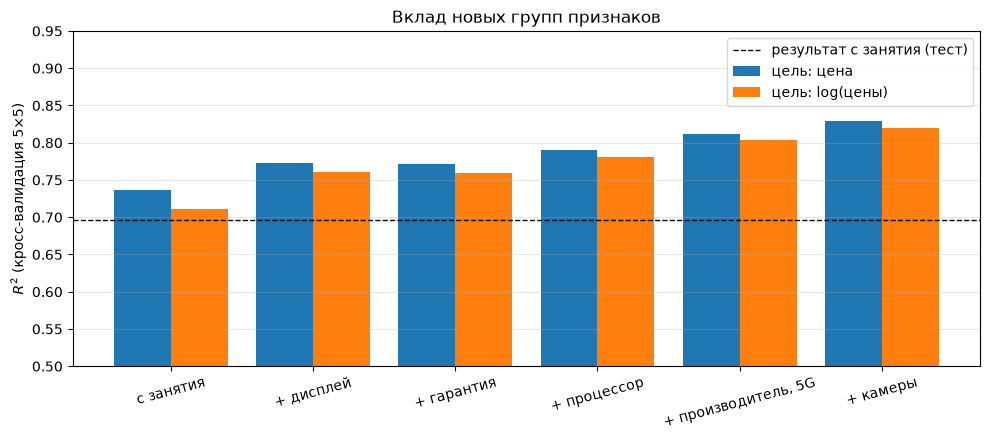

In [30]:
piv = abl.pivot(index="признаки", columns="цель", values="R2 CV").loc[list(groups)]
fig, ax = plt.subplots(figsize=(10, 4.5))
xs = np.arange(len(piv))
ax.bar(xs - 0.2, piv["price"], 0.4, label="цель: цена")
ax.bar(xs + 0.2, piv["log"], 0.4, label="цель: log(цены)")
ax.axhline(0.696, color="k", ls="--", lw=1, label="результат с занятия (тест)")
ax.set_xticks(xs); ax.set_xticklabels(piv.index, rotation=15)
ax.set_ylabel("$R^2$ (кросс-валидация 5×5)"); ax.set_ylim(0.5, 0.95); ax.legend(); ax.grid(alpha=0.3, axis="y")
ax.set_title("Вклад новых групп признаков")
fig.tight_layout(); fig.savefig("figures/phones_ablation.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. «Отмена» скидки

В столбце `Price` — цена **со скидкой**. Размер скидки — маркетинговое решение магазина, слабо связанное с характеристиками телефона, а исходная цена (MRP) определяется именно характеристиками. Поэтому можно «отменить» скидку: $\text{MRP} = \dfrac{\text{Price}}{1 - \text{discount}}$, обучить модель предсказывать MRP, а итоговую цену получать обратно: $\widehat{\text{Price}} = \widehat{\text{MRP}}\cdot(1-\text{discount})$. Метрику по-прежнему считаю для `Price`, чтобы сравнение было честным.

Заодно подбираю регуляризацию (Ridge).

In [31]:
num_all = [c for g in groups.values() for c in g[0]]
bin_all = [c for g in groups.values() for c in g[1]]
cat_all = [c for g in groups.values() for c in g[2]]
num_log = [log_swap.get(c, c) for c in num_all]

rows = []
for target in ("price", "mrp", "log", "log_mrp"):
    n_used = num_log if "log" in target else num_all
    for alpha in (0, 0.3, 1, 3, 10):
        model = LinearRegression() if alpha == 0 else Ridge(alpha=alpha)
        tr_r2, cv_mean, cv_std = cv_r2(TargetWrapper(build(n_used, bin_all, cat_all, model), target))
        rows.append({"цель": target, "alpha": alpha, "R2 train": tr_r2, "R2 CV": cv_mean, "std CV": cv_std})
disc = pd.DataFrame(rows)
RESULTS["discount"] = disc.round(4).to_dict(orient="records")
disc.pivot(index="alpha", columns="цель", values="R2 CV").round(4)

цель,log,log_mrp,mrp,price
alpha,,,,
0.0,0.8204,0.8208,0.8234,0.8296
0.3,0.8217,0.8221,0.8249,0.8301
1.0,0.8224,0.8227,0.8256,0.8300
3.0,0.8218,0.8219,0.8258,0.8294
10.0,0.8166,0.8160,0.8244,0.8270


In [32]:
best = disc.loc[disc["R2 CV"].idxmax()]
print(f"Лучший вариант по кросс-валидации: цель = {best['цель']}, alpha = {best['alpha']}, R2 CV = {best['R2 CV']:.4f}")

def make_model(target, alpha, num, binf, cat):
    n_used = [log_swap.get(c, c) for c in num] if "log" in target else num
    return TargetWrapper(build(n_used, binf, cat, LinearRegression() if alpha == 0 else Ridge(alpha=alpha)), target)

final_models = {
    "Признаки с занятия, цель = цена": make_model("price", 0, *groups["с занятия"]),
    "Признаки с занятия, цель = MRP (отмена скидки)": make_model("mrp", 0, *groups["с занятия"]),
    "Все признаки, цель = цена": make_model("price", 0, num_all, bin_all, cat_all),
    "Все признаки, цель = MRP (отмена скидки)": make_model("mrp", 0, num_all, bin_all, cat_all),
    f"Лучшая по CV: цель = {best['цель']}, alpha = {best['alpha']}": make_model(best["цель"], best["alpha"], num_all, bin_all, cat_all),
}
test_rows = []
for nm, m in final_models.items():
    m.fit(X_train, Y_train)
    test_rows.append({"модель": nm, "R2 train": r2_score(Y_train, m.predict(X_train)),
                      "R2 test": r2_score(Y_test, m.predict(X_test)),
                      "MAPE test": mean_absolute_percentage_error(Y_test, m.predict(X_test))})
test_df = pd.DataFrame(test_rows).set_index("модель")
RESULTS["test"] = test_df.round(4).reset_index().to_dict(orient="records")
RESULTS["best"] = {"target": best["цель"], "alpha": float(best["alpha"]), "r2_cv": float(best["R2 CV"])}
test_df.round(4)

Лучший вариант по кросс-валидации: цель = price, alpha = 0.3, R2 CV = 0.8301


,R2 train,R2 test,MAPE test
модель,,,
"Признаки с занятия, цель = цена",0.7440,0.7726,0.2638
"Признаки с занятия, цель = MRP (отмена скидки)",0.7301,0.7475,0.2820
"Все признаки, цель = цена",0.8674,0.8576,0.2439
"Все признаки, цель = MRP (отмена скидки)",0.8660,0.8312,0.2554
"Лучшая по CV: цель = price, alpha = 0.3",0.8667,0.8596,0.2397


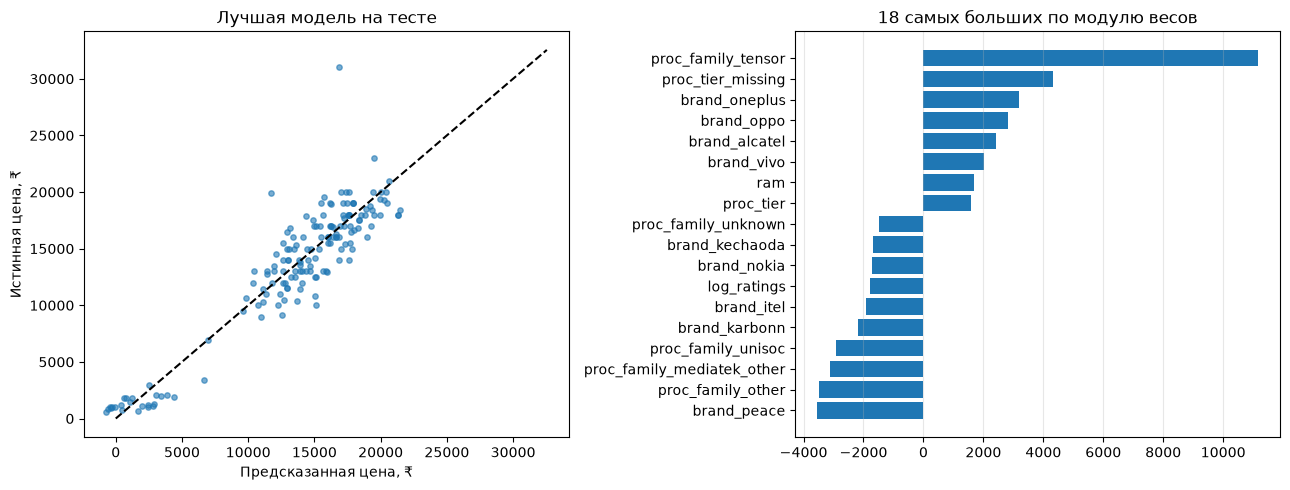

In [33]:
m = list(final_models.values())[-1]
p = m.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(p, Y_test, alpha=0.6, s=15)
lim = [0, max(p.max(), Y_test.max()) * 1.05]; ax[0].plot(lim, lim, "k--")
ax[0].set_xlabel("Предсказанная цена, ₹"); ax[0].set_ylabel("Истинная цена, ₹"); ax[0].set_title("Лучшая модель на тесте")
names = m.pipe[0].get_feature_names_out()
coef = pd.Series(m.pipe[-1].coef_, index=[n.split("__")[1] for n in names])
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:18]).sort_values()
ax[1].barh(top.index, top.values); ax[1].set_title("18 самых больших по модулю весов"); ax[1].grid(alpha=0.3, axis="x")
fig.tight_layout(); fig.savefig("figures/phones_final.png", dpi=150, bbox_inches="tight"); plt.show()
with open("figures/results_phones.json", "w") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2, default=float)

## 8. Почему «отмена» скидки не помогла

На занятии отмена скидки дала небольшой прирост, а у меня — наоборот, небольшое ухудшение (и по кросс-валидации, и на тесте). Проверю связь скидки с ценами.

Корреляция скидки с ценой со скидкой (Price): -0.308
Корреляция скидки с ценой без скидки (MRP):   -0.002
Price: макс = 38999, доля > 20000: 3.6%
MRP:   макс = 49999, доля > 20000: 33.9%
Средняя скидка: кнопочные телефоны 34.2%, телефоны дешевле 5000 ₹ 26.9%, остальные 18.8%
Коэффициент вариации: Price 0.428, MRP 0.436
Средний разброс R2 между фолдами: 0.041


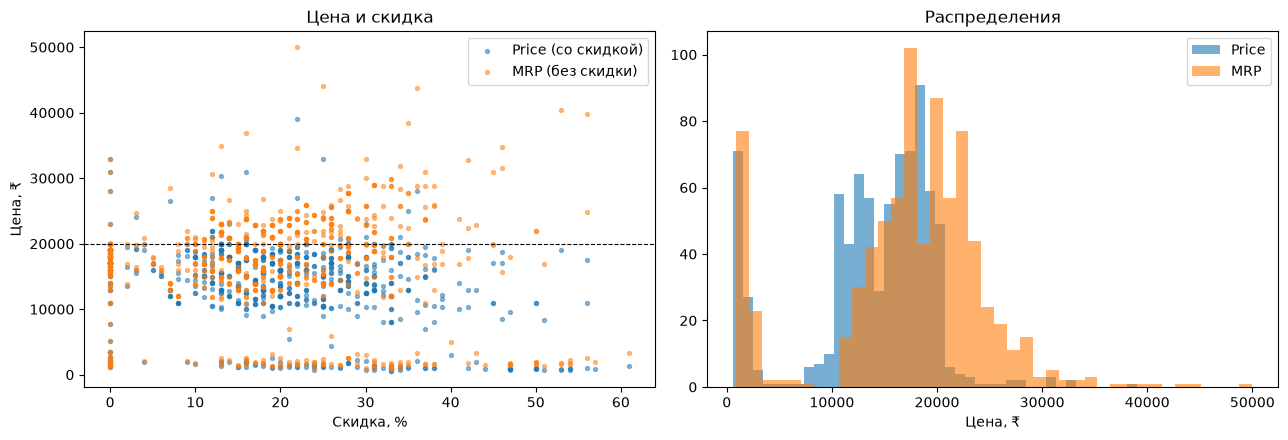

In [34]:
print(f"Корреляция скидки с ценой со скидкой (Price): {df['discount'].corr(df['Price']):.3f}")
print(f"Корреляция скидки с ценой без скидки (MRP):   {df['discount'].corr(df['mrp']):.3f}")
print(f"Price: макс = {df['Price'].max():.0f}, доля > 20000: {(df['Price'] > 20000).mean():.1%}")
print(f"MRP:   макс = {df['mrp'].max():.0f}, доля > 20000: {(df['mrp'] > 20000).mean():.1%}")
print(f"Средняя скидка: кнопочные телефоны {df.loc[df.is_keypad == 1, 'discount'].mean():.1%}, "
      f"телефоны дешевле 5000 ₹ {df.loc[df.Price < 5000, 'discount'].mean():.1%}, остальные {df.loc[df.Price >= 5000, 'discount'].mean():.1%}")
print(f"Коэффициент вариации: Price {df['Price'].std() / df['Price'].mean():.3f}, MRP {df['mrp'].std() / df['mrp'].mean():.3f}")
cv_std = disc.loc[disc['цель'].isin(['price', 'mrp']), 'std CV'].mean()
print(f"Средний разброс R2 между фолдами: {cv_std:.3f}")
RESULTS["discount_stats"] = {"cheap": float(df.loc[df.Price < 5000, 'discount'].mean()), "rest": float(df.loc[df.Price >= 5000, 'discount'].mean()),
                             "mrp_over_20000": float((df['mrp'] > 20000).mean()), "cv_std": float(cv_std)}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(df["discount"] * 100, df["Price"], s=8, alpha=0.5, label="Price (со скидкой)")
ax[0].scatter(df["discount"] * 100, df["mrp"], s=8, alpha=0.5, label="MRP (без скидки)")
ax[0].axhline(20000, color="k", ls="--", lw=0.8)
ax[0].set_xlabel("Скидка, %"); ax[0].set_ylabel("Цена, ₹"); ax[0].legend(); ax[0].set_title("Цена и скидка")
ax[1].hist(df["Price"], bins=40, alpha=0.6, label="Price"); ax[1].hist(df["mrp"], bins=40, alpha=0.6, label="MRP")
ax[1].set_xlabel("Цена, ₹"); ax[1].legend(); ax[1].set_title("Распределения")
fig.tight_layout(); fig.savefig("figures/phones_discount.png", dpi=150, bbox_inches="tight"); plt.show()
RESULTS["discount_corr"] = {"price": float(df['discount'].corr(df['Price'])), "mrp": float(df['discount'].corr(df['mrp']))}
with open("figures/results_phones.json", "w") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2, default=float)

Получилось интересно: скидка **не связана** с ценой без скидки (MRP), но заметно **отрицательно** связана с реальной ценой продажи — самые большие «скидки» у самых дешёвых телефонов. Это похоже на типичную практику маркетплейсов: MRP — это «витринная» цена, которую продавец может завысить, чтобы показать большую скидку, а реальная рыночная стоимость телефона, определяемая характеристиками, — это как раз `Price`. Тогда при «отмене» скидки в целевую переменную добавляется шум от размера скидки, и предсказывать MRP по характеристикам оказывается не проще, а сложнее.

В итоге «отмена» скидки в моей постановке даёт $R^2$ чуть ниже (на 0.005 по кросс-валидации). Разница меньше разброса между фолдами — т.е. эффект в пределах шума, как и улучшение на занятии (0.696 → 0.701). Делать вывод «отмена скидки помогает/мешает» на этих данных нельзя, а модель на исходной цене проще.

## Итог

- Обработка оставшихся текстовых признаков подняла $R^2$ (кросс-валидация) с 0.737 до 0.830, а на тесте — с 0.773 до 0.860 (ориентир с занятия — 0.70 на другом разбиении).
- Больше всего дали дисплей (по сути отделяет кнопочные телефоны от смартфонов и FullHD от HD), производитель и камеры. Процессор тоже полезен, но слабее, чем ожидалось — его информация частично дублируется памятью и 5G. Гарантия почти ничего не добавила: у 97% телефонов она 12 месяцев.
- Регуляризация влияет слабо: лучший `alpha` для Ridge ≈ 0.3–1, прирост — тысячные доли.
- В «сырых» данных нашлись сдвиги столбцов (гарантия в столбце процессора, характеристики в столбце гарантии) и опечатка в диагонали, которая ломала модель на логарифмической цели. Это хороший пример того, почему распределения признаков нужно проверять до обучения.